Assignment 2 – Data Visualization

Import Libraries and Load the Dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset("taxis")
print(df.head())

               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Side South      

In [3]:
print("Dataset Shape:", df.shape)
df.info()
print(df.describe())



Dataset Shape: (6433, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[ns]
 1   dropoff          6433 non-null   datetime64[ns]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   object        
 9   payment          6389 non-null   object        
 10  pickup_zone      6407 non-null   object        
 11  dropoff_zone     6388 non-null   object        
 12  pickup_borough   6407 non-null   object        
 13  dropoff_borough  6388 non-null   object        
dtypes: datetime64[

Handling Missing Values

In [4]:
print(df.isnull().sum())

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [5]:
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [6]:

df = df.dropna(subset=["pickup", "fare"])

numerical_columns = df.select_dtypes(include="number").columns
for col in numerical_columns:
    df[col] = df[col].fillna(df[col].median())
categorical_columns = df.select_dtypes(
    include=["object", "category", "string"]
).columns

for col in categorical_columns:
    if df[col].isnull().any():
        mode_value = df[col].mode()

        if not mode_value.empty:
            df[col] = df[col].fillna(mode_value.iloc[0])
print("Missing values after handling:")
print(df.isnull().sum())

Missing values after handling:
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


Visualizations using Matplotlib/Pandas Plot

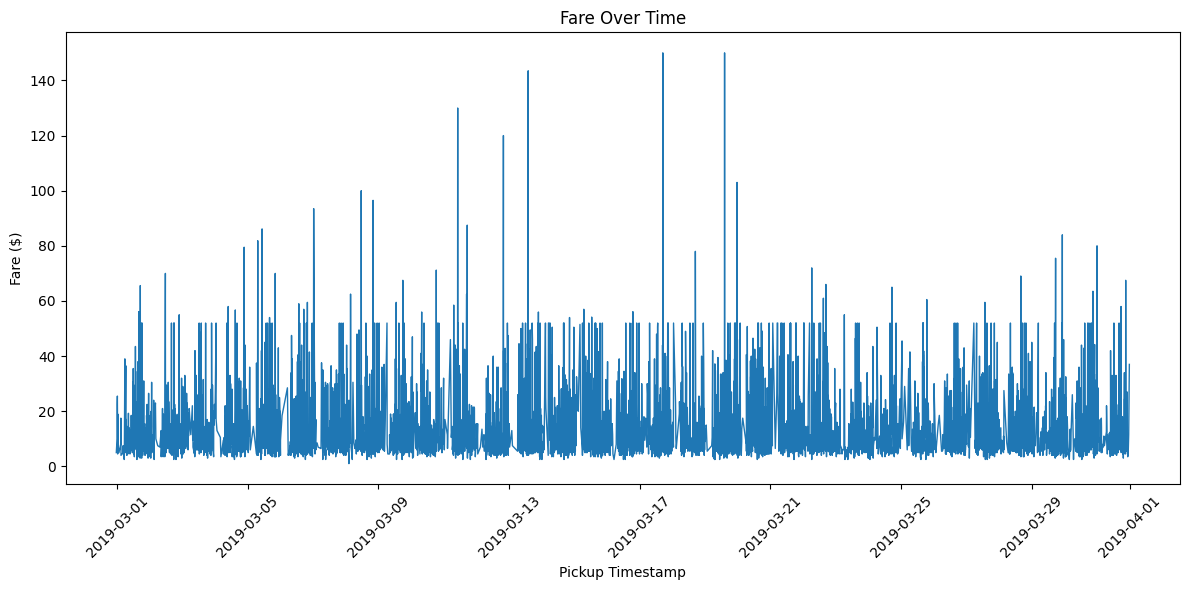

In [7]:
  #Line Chart
df["pickup"] = pd.to_datetime(df["pickup"])
df = df.sort_values("pickup")

plt.figure(figsize=(12, 6))

plt.plot(df["pickup"], df["fare"], linewidth=1)

plt.title("Fare Over Time")
plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare ($)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

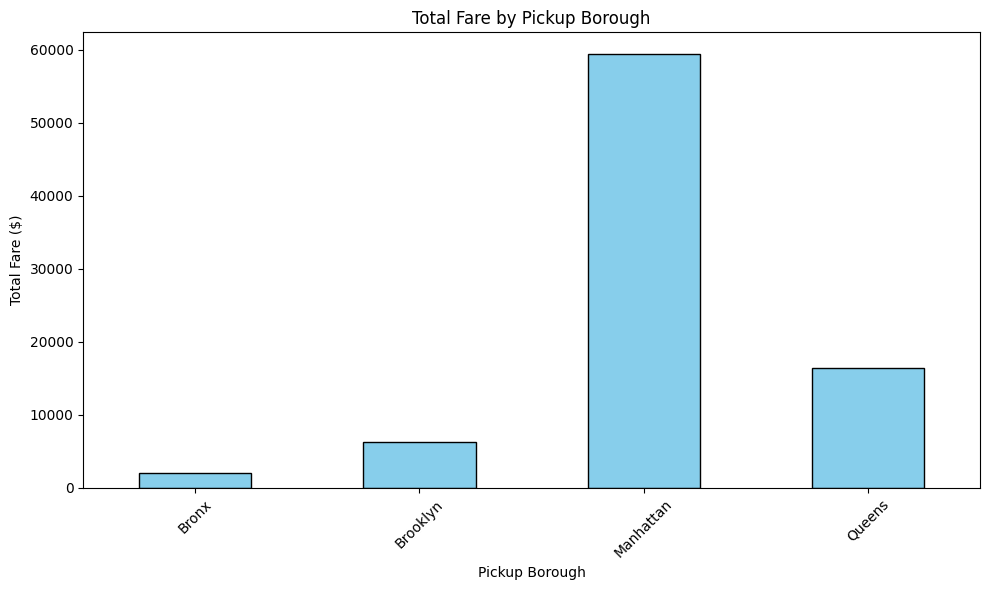

In [8]:
# Bar Chart
borough_fare = df.groupby(
    "pickup_borough"
)["fare"].sum()
plt.figure(figsize=(10, 6))

borough_fare.plot(
    kind="bar",
    color="skyblue",
    edgecolor="black"
)

plt.title("Total Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare ($)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

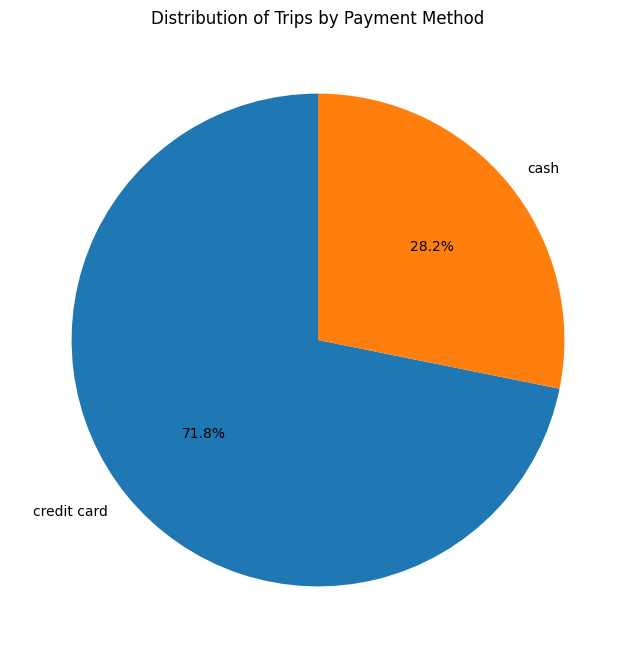

In [9]:
#Pie Chart
payment_counts = df["payment"].value_counts()

# Create pie chart
plt.figure(figsize=(8, 8))
plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Trips by Payment Method")
plt.show()

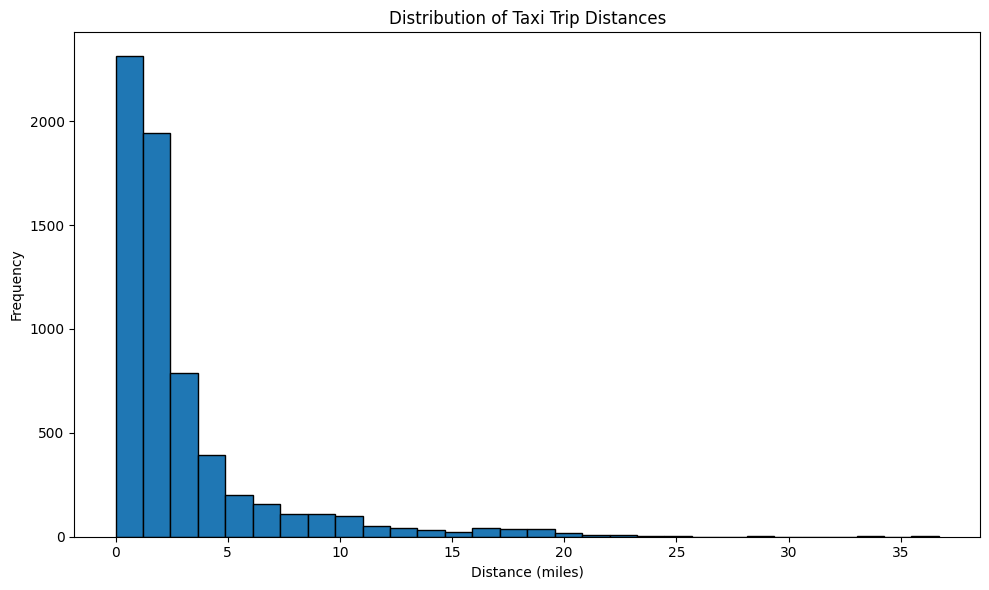

In [10]:
#Histogram
plt.figure(figsize=(10, 6))

plt.hist(
    df["distance"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Taxi Trip Distances")
plt.xlabel("Distance (miles)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

<Figure size 1000x600 with 0 Axes>

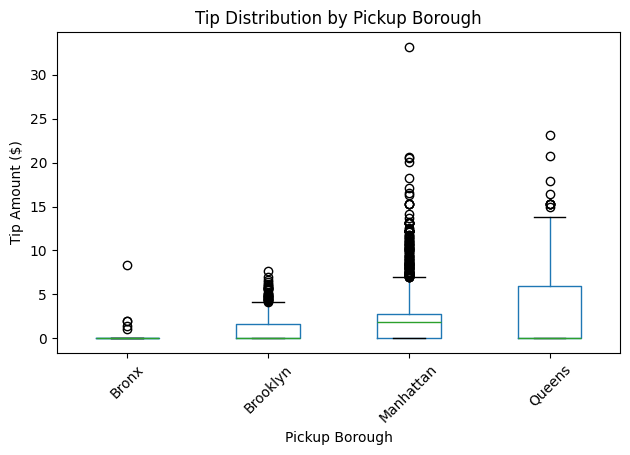

In [11]:
#Boxplot
plt.figure(figsize=(10, 6))

df.boxplot(
    column="tip",
    by="pickup_borough",
    grid=False
)

plt.title("Tip Distribution by Pickup Borough")
plt.suptitle("")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount ($)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Visualizations Using Seaborn

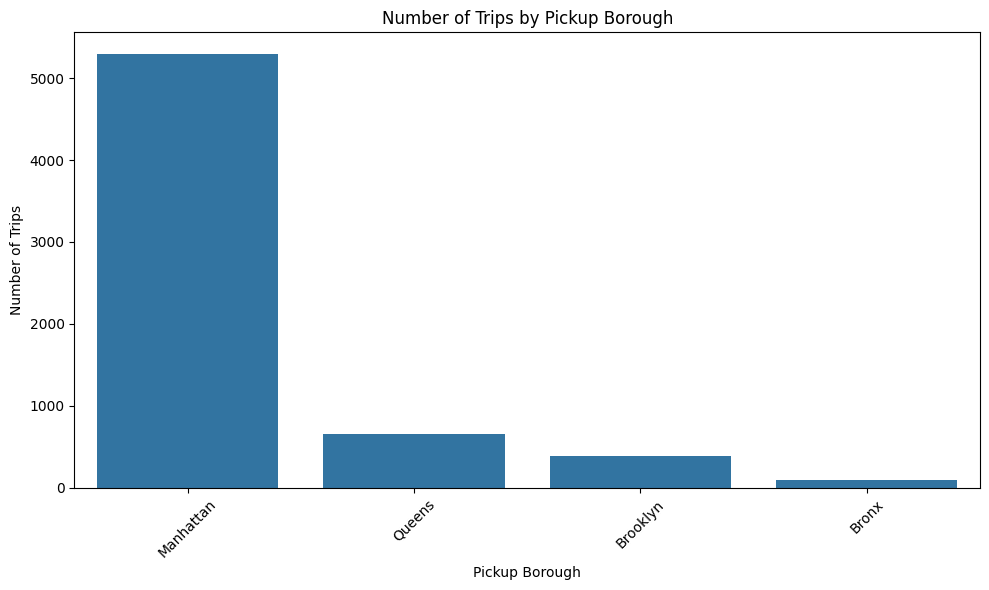

In [12]:
#Count plot
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="pickup_borough",
    order=df["pickup_borough"].value_counts().index
)

plt.title("Number of Trips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

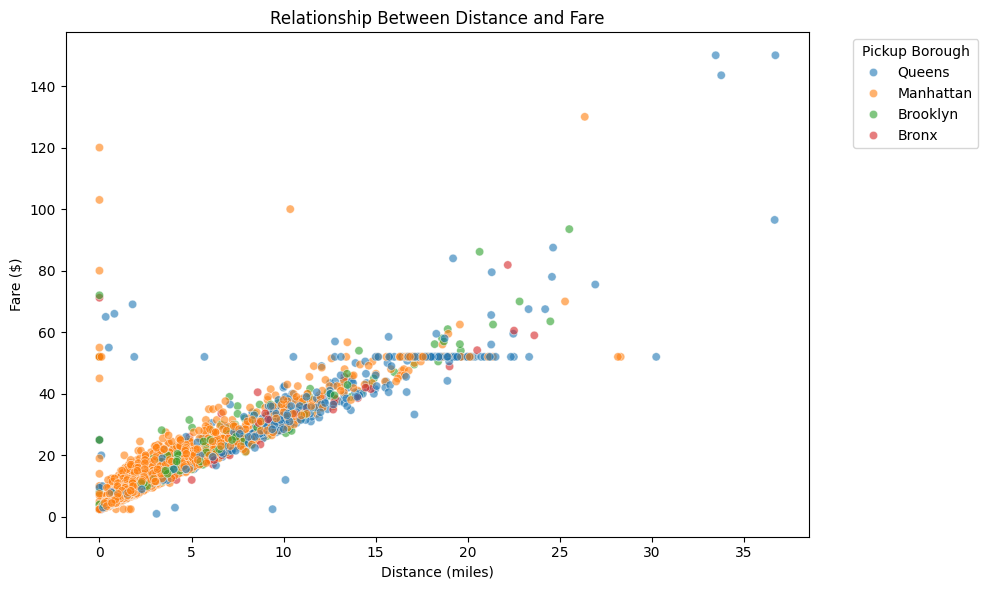

In [13]:
#Scatter Plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="distance",
    y="fare",
    hue="pickup_borough",
    alpha=0.6
)

plt.title("Relationship Between Distance and Fare")
plt.xlabel("Distance (miles)")
plt.ylabel("Fare ($)")
plt.legend(title="Pickup Borough", bbox_to_anchor=(1.05, 1))

plt.tight_layout()
plt.show()

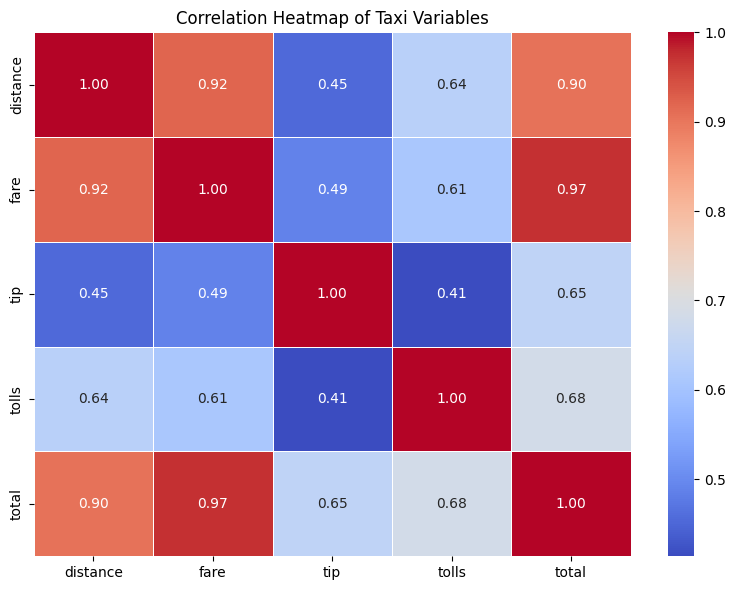

In [14]:
#Heat Map
numeric_data = df[
    ["distance", "fare", "tip", "tolls", "total"]
]

correlation_matrix = numeric_data.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Taxi Variables")
plt.tight_layout()
plt.show()

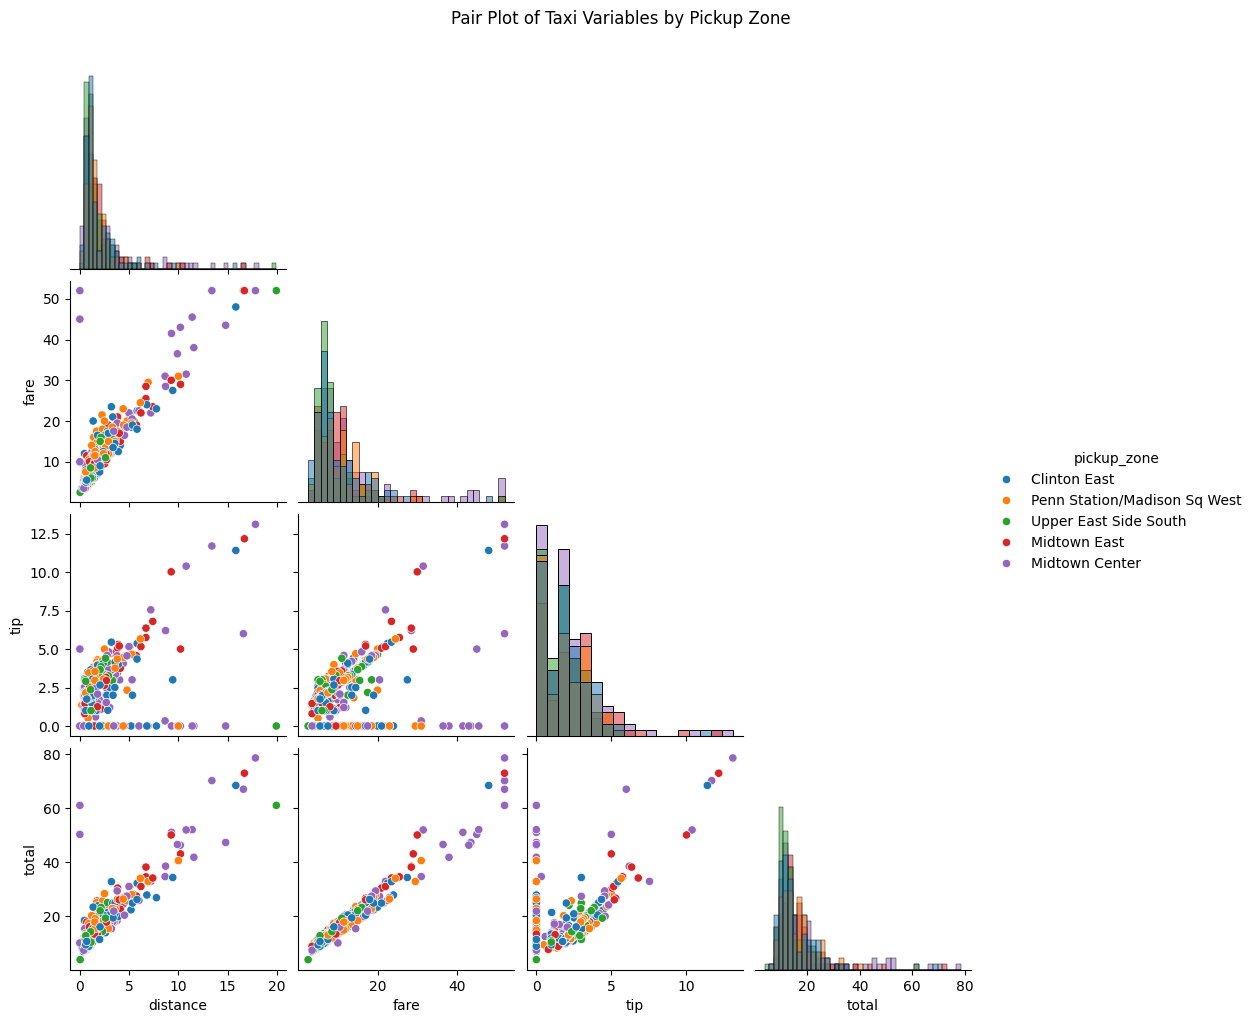

In [ ]:
# Pair Plot
pairplot_data = df[
    ["distance", "fare", "tip", "total", "pickup_zone"]
].dropna()


top_zones = pairplot_data["pickup_zone"].value_counts().head(5).index

pairplot_data = pairplot_data[
    pairplot_data["pickup_zone"].isin(top_zones)
]

pairplot_data = pairplot_data.sample(
    n=min(500, len(pairplot_data)),
    random_state=42
)

sns.pairplot(
    pairplot_data,
    vars=["distance", "fare", "tip", "total"],
    hue="pickup_zone",
    diag_kind="hist",
    corner=True
)

plt.suptitle(
    "Pair Plot of Taxi Variables by Pickup Zone",
    y=1.02
)

plt.show()

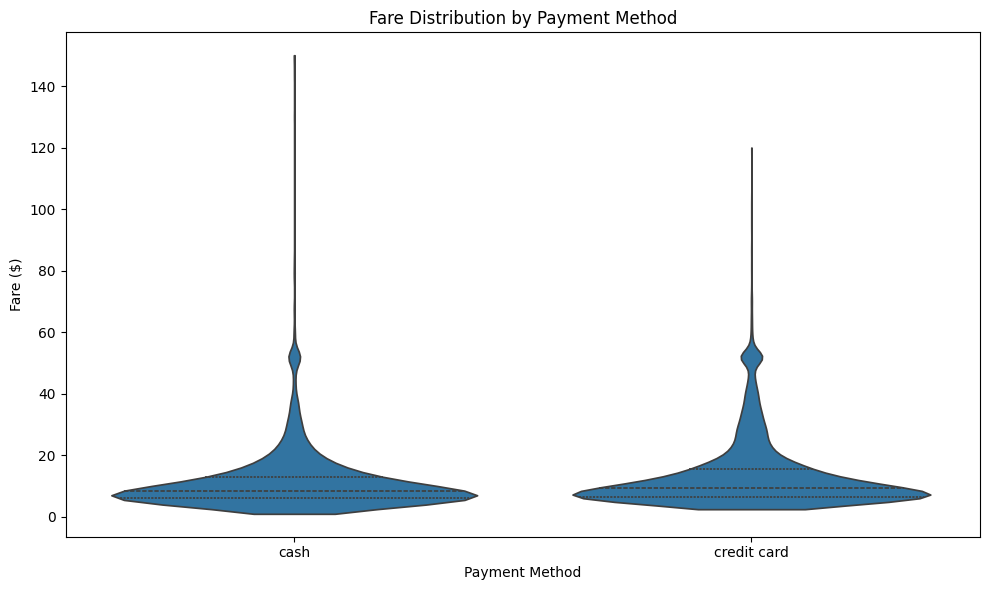

In [17]:
#Violin Plot
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x="payment",
    y="fare",
    inner="quartile",
    cut=0
)

plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare ($)")

plt.tight_layout()
plt.show()

In [ ]:

print("Final Dataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())

print("\nFirst Five Rows:")
print(df.head())

Final Dataset Shape: (6433, 14)

Missing Values:
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

First Five Rows:
                  pickup             dropoff  passengers  distance  fare  tip  \
6203 2019-02-28 23:29:03 2019-02-28 23:32:35           1      0.90   5.0  0.0   
884  2019-03-01 00:03:29 2019-03-01 00:13:32           3      2.16  10.0  2.0   
2882 2019-03-01 00:08:32 2019-03-01 00:29:47           3      7.35  22.5  1.0   
4212 2019-03-01 00:15:53 2019-03-01 00:47:58           1      7.00  25.5  7.3   
661  2019-03-01 00:29:22 2019-03-01 00:32:48           4      0.74   4.5  1.0   

      tolls  total   color      payment                    pickup_zone  \
6203    0.0    6.3   green         cash                    Old As